Total Rows: 10000
Duplicate Feature Rows Found: 2500
Clean Training Set Rows: 7500

--- CLASS DISTRIBUTION ---
            Count  Percent (%)
class_name                    
Sedan        2539        33.85
SUV          2490        33.20
Sports Car   2471        32.95

--- CLASS-CONDITIONAL MEANS & STANDARD DEVIATIONS ---
                     Feature            Sedan              SUV       Sports Car
       engine_displacement_l      1.97 ± 0.48      2.46 ± 0.50      2.86 ± 0.49
               horsepower_hp   230.74 ± 70.89   282.97 ± 74.72   378.60 ± 72.86
           vehicle_weight_kg 1506.02 ± 208.97 1951.66 ± 214.52 1453.41 ± 203.57
                wheelbase_mm 2698.78 ± 113.60 2961.89 ± 113.41 2674.89 ± 113.39
           vehicle_length_mm 4503.52 ± 251.79 5041.74 ± 237.08 4434.51 ± 250.49
            vehicle_width_mm  1781.21 ± 80.24  1962.87 ± 73.12  1765.99 ± 76.86
           vehicle_height_mm 1557.14 ± 124.19 1610.19 ± 125.35 1418.01 ± 113.64
        fuel_tank_capacity_l    55.62 ±

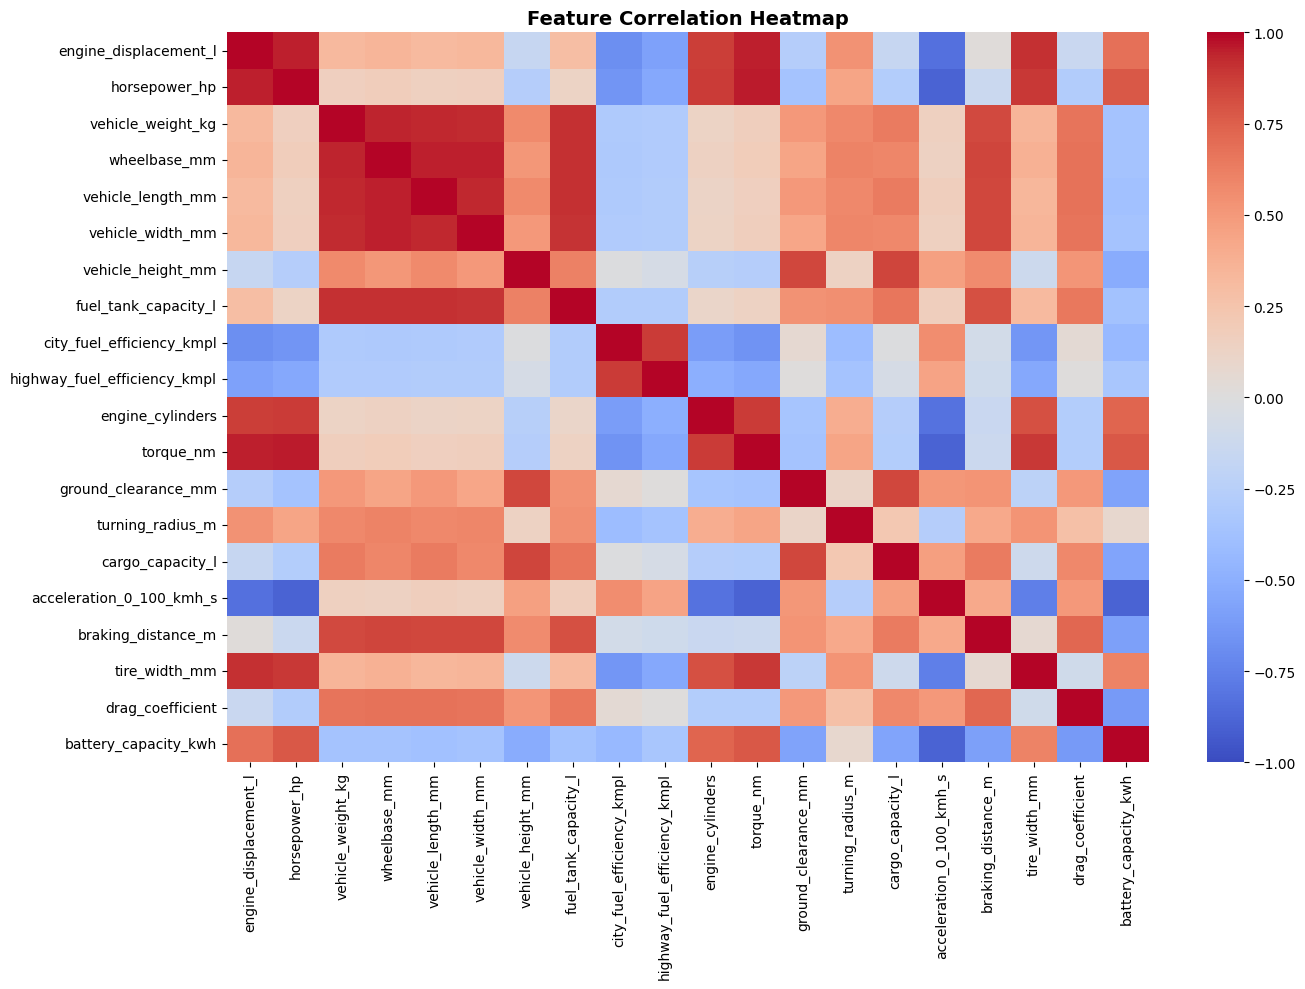

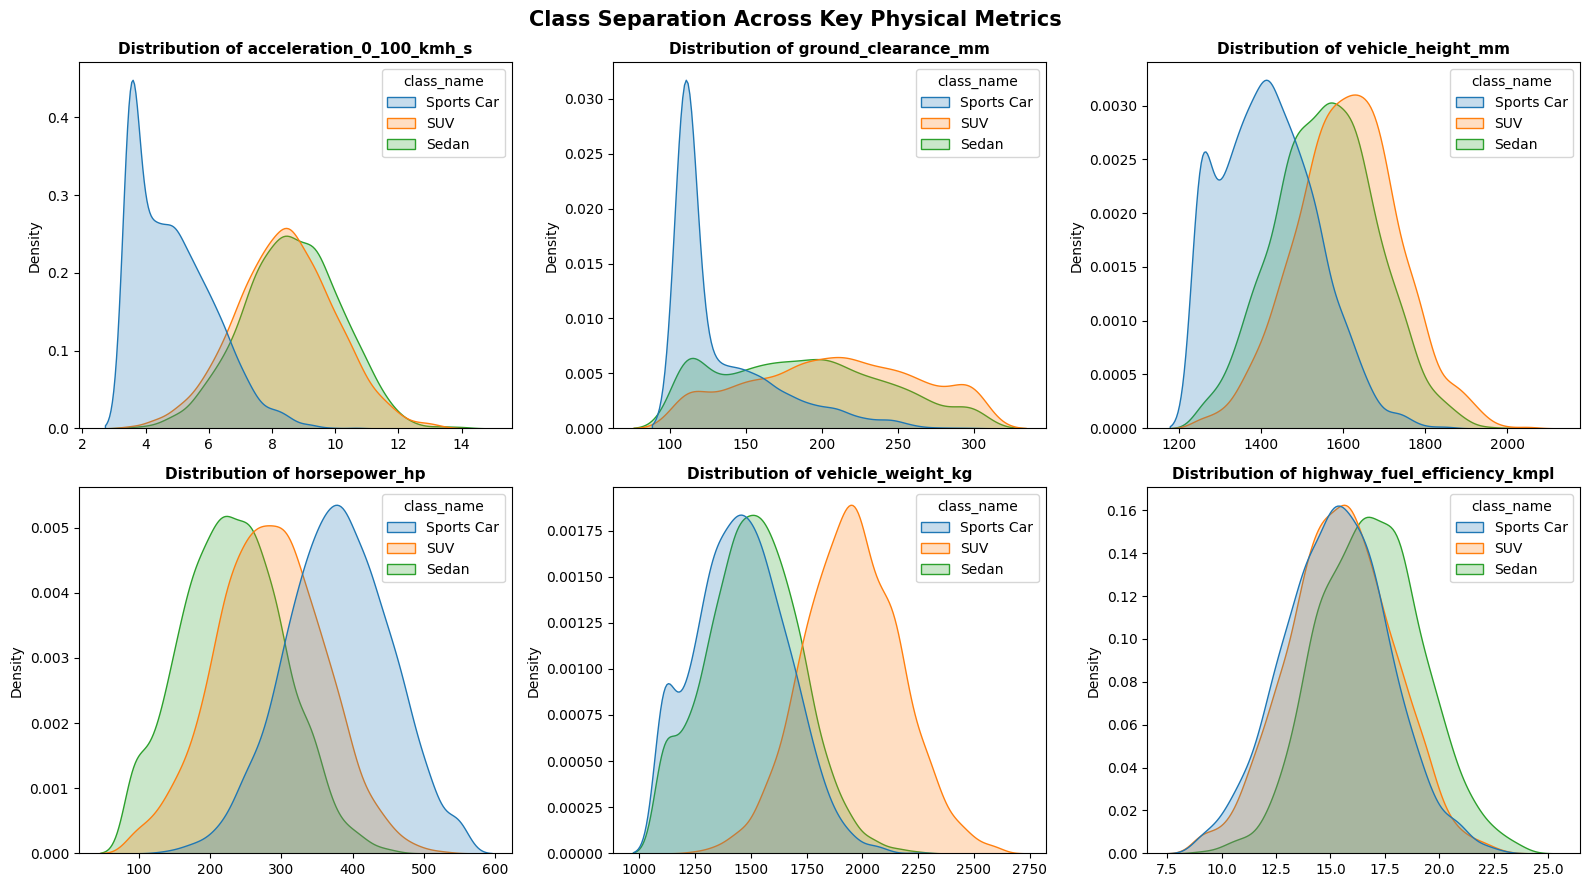

In [5]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# 1. Load Data
TRAIN_PATH = '/kaggle/input/competitions/vehicle-type-classification/vehicle_train_10000.csv'
TEST_PATH = '/kaggle/input/competitions/vehicle-type-classification/vehicle_test.csv'

df_train = pd.read_csv(TRAIN_PATH)
df_test = pd.read_csv(TEST_PATH)

target_col = 'vehicle_class'
id_col = 'vehicle_id'
feature_cols = [c for c in df_train.columns if c not in [id_col, target_col]]

# 2. Deduplication Audit
dup_count = df_train.duplicated(subset=feature_cols).sum()
print("=" * 60)
print(f"Total Rows: {len(df_train)}")
print(f"Duplicate Feature Rows Found: {dup_count}")
print("=" * 60)

# Drop duplicates
df_clean = df_train.drop_duplicates(subset=feature_cols).reset_index(drop=True)
print(f"Clean Training Set Rows: {len(df_clean)}")

# 3. Class Balance Breakdown
class_names = {0: 'Sedan', 1: 'SUV', 2: 'Sports Car'}
df_clean['class_name'] = df_clean[target_col].map(class_names)

print("\n--- CLASS DISTRIBUTION ---")
class_counts = df_clean['class_name'].value_counts()
class_pct = df_clean['class_name'].value_counts(normalize=True) * 100
print(pd.DataFrame({'Count': class_counts, 'Percent (%)': class_pct.round(2)}))

# 4. Class-Conditional Summary Statistics (Robust Aggregation)
print("\n--- CLASS-CONDITIONAL MEANS & STANDARD DEVIATIONS ---")
summary_rows = []
for col in feature_cols:
    row = {'Feature': col}
    for c_id, c_name in class_names.items():
        subset = df_clean[df_clean[target_col] == c_id][col]
        row[c_name] = f"{subset.mean():.2f} ± {subset.std():.2f}"
    summary_rows.append(row)

stats_df = pd.DataFrame(summary_rows)
pd.set_option('display.max_rows', 50)
pd.set_option('display.width', 1000)
print(stats_df.to_string(index=False))

# 5. Multicollinearity: High Correlations (|r| > 0.70)
print("\n--- HIGH CORRELATIONS (|r| > 0.70) ---")
corr_matrix = df_clean[feature_cols].corr()
upper_tri = corr_matrix.where(np.triu(np.ones(corr_matrix.shape), k=1).astype(bool))
high_corr = upper_tri.stack().reset_index()
high_corr.columns = ['Feature 1', 'Feature 2', 'Pearson r']
high_corr = high_corr[high_corr['Pearson r'].abs() > 0.70].sort_values(by='Pearson r', ascending=False)

if len(high_corr) > 0:
    print(high_corr.round(3).to_string(index=False))
else:
    print("No pairs with Pearson |r| > 0.70 found.")

# 6. Plots: Correlation Heatmap
plt.figure(figsize=(14, 10))
sns.heatmap(corr_matrix, cmap='coolwarm', annot=False, vmin=-1, vmax=1)
plt.title("Feature Correlation Heatmap", fontsize=14, weight='bold')
plt.tight_layout()
plt.show()

# 7. Plots: Distribution Comparison for Key Features
key_features = [
    'acceleration_0_100_kmh_s', 'ground_clearance_mm', 
    'vehicle_height_mm', 'horsepower_hp', 
    'vehicle_weight_kg', 'highway_fuel_efficiency_kmpl'
]

fig, axes = plt.subplots(2, 3, figsize=(16, 9))
axes = axes.flatten()

for i, col in enumerate(key_features):
    sns.kdeplot(data=df_clean, x=col, hue='class_name', common_norm=False, fill=True, ax=axes[i])
    axes[i].set_title(f"Distribution of {col}", fontsize=11, weight='bold')
    axes[i].set_xlabel("")

plt.suptitle("Class Separation Across Key Physical Metrics", fontsize=15, weight='bold')
plt.tight_layout()
plt.show()

DATA PREPARATION SUMMARY
Original Feature Count   : 20
Engineered Features Added: 7
Columns Dropped (|r|>0.85): 16
Dropped List             : ['horsepower_hp', 'wheelbase_mm', 'vehicle_length_mm', 'vehicle_width_mm', 'fuel_tank_capacity_l', 'highway_fuel_efficiency_kmpl', 'engine_cylinders', 'torque_nm', 'acceleration_0_100_kmh_s', 'braking_distance_m', 'tire_width_mm', 'battery_capacity_kwh', 'power_to_weight', 'slenderness_lh', 'clearance_ratio', 'cargo_to_weight']
Final Prepared Features  : 11

Retained Features for Modeling:
['engine_displacement_l', 'vehicle_weight_kg', 'vehicle_height_mm', 'city_fuel_efficiency_kmpl', 'ground_clearance_mm', 'turning_radius_m', 'cargo_capacity_l', 'drag_coefficient', 'torque_per_displacement', 'aspect_ratio_hw', 'fuel_eff_spread']


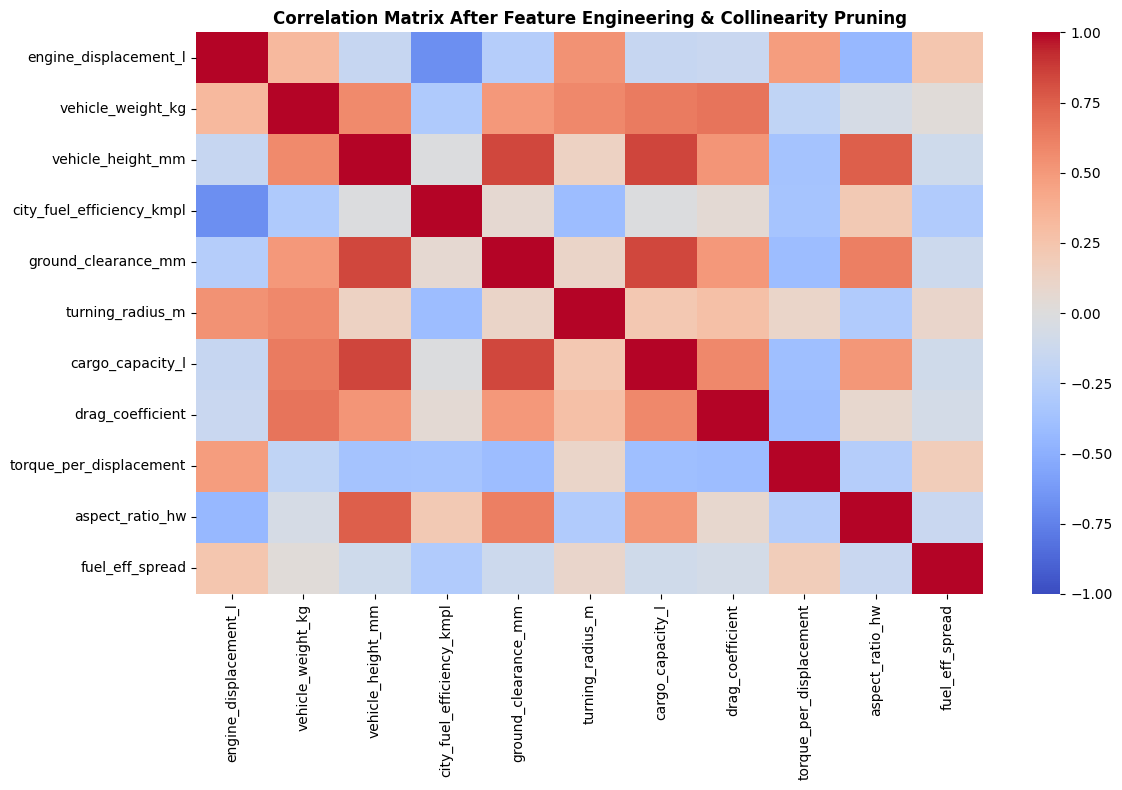

In [6]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# 1. Load Clean Deduplicated Data
df_clean = df_train.drop_duplicates(subset=feature_cols).reset_index(drop=True)
y = df_clean[target_col].values

# 2. Feature Engineering Function (Domain Ratios)
def engineer_physics_features(df):
    df = df.copy()
    
    # Dynamics & Powertrain efficiency
    df['power_to_weight'] = df['horsepower_hp'] / (df['vehicle_weight_kg'] + 1e-5)
    df['torque_per_displacement'] = df['torque_nm'] / (df['engine_displacement_l'] + 1e-5)
    
    # Geometric vehicle posture (differentiates SUV vs Sedan vs Sports Car)
    df['aspect_ratio_hw'] = df['vehicle_height_mm'] / (df['vehicle_width_mm'] + 1e-5)
    df['slenderness_lh'] = df['vehicle_length_mm'] / (df['vehicle_height_mm'] + 1e-5)
    df['clearance_ratio'] = df['ground_clearance_mm'] / (df['vehicle_height_mm'] + 1e-5)
    
    # Practical utility
    df['cargo_to_weight'] = df['cargo_capacity_l'] / (df['vehicle_weight_kg'] + 1e-5)
    df['fuel_eff_spread'] = df['highway_fuel_efficiency_kmpl'] - df['city_fuel_efficiency_kmpl']
    
    return df

df_engineered = engineer_physics_features(df_clean[feature_cols])

# 3. Systematic Multicollinearity Pruning (|r| > 0.85)
def prune_collinear_features(df, threshold=0.85):
    """
    Iteratively removes features that have Pearson correlation > threshold
    with an earlier feature, retaining the first encountered feature.
    """
    corr_matrix = df.corr().abs()
    upper_tri = corr_matrix.where(np.triu(np.ones(corr_matrix.shape), k=1).astype(bool))
    
    to_drop = [col for col in upper_tri.columns if any(upper_tri[col] > threshold)]
    df_pruned = df.drop(columns=to_drop)
    return df_pruned, to_drop

df_prepared, dropped_cols = prune_collinear_features(df_engineered, threshold=0.85)

print("=" * 65)
print("DATA PREPARATION SUMMARY")
print("=" * 65)
print(f"Original Feature Count   : {len(feature_cols)}")
print(f"Engineered Features Added: 7")
print(f"Columns Dropped (|r|>0.85): {len(dropped_cols)}")
print(f"Dropped List             : {dropped_cols}")
print(f"Final Prepared Features  : {df_prepared.shape[1]}")
print("=" * 65)
print("\nRetained Features for Modeling:")
print(list(df_prepared.columns))

# 4. Verification Heatmap of Prepared Data
plt.figure(figsize=(12, 8))
sns.heatmap(df_prepared.corr(), cmap='coolwarm', annot=False, vmin=-1, vmax=1)
plt.title("Correlation Matrix After Feature Engineering & Collinearity Pruning", fontsize=12, weight='bold')
plt.tight_layout()
plt.show()

In [7]:
from sklearn.model_selection import StratifiedKFold
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.naive_bayes import GaussianNB
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score

skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

def evaluate_model(clf, X_mat, y_vec):
    oof_preds = np.zeros(len(y_vec))
    for train_idx, val_idx in skf.split(X_mat, y_vec):
        pipe = Pipeline([
            ('scaler', StandardScaler()),
            ('model', clf)
        ])
        pipe.fit(X_mat[train_idx], y_vec[train_idx])
        oof_preds[val_idx] = pipe.predict(X_mat[val_idx])
    return accuracy_score(y_vec, oof_preds)

# Compare on Raw vs Prepared features
X_raw = df_clean[feature_cols].values
X_prep = df_prepared.values

print("\n--- MODEL PERFORMANCE COMPARISON ---")

# 1. Gaussian Naive Bayes
gnb_raw_acc = evaluate_model(GaussianNB(var_smoothing=1e-1), X_raw, y)
gnb_prep_acc = evaluate_model(GaussianNB(var_smoothing=1e-1), X_prep, y)
print(f"Gaussian Naive Bayes (Raw Features)      : {gnb_raw_acc:.4f}")
print(f"Gaussian Naive Bayes (Prepared Features) : {gnb_prep_acc:.4f}")

# 2. Multinomial Logistic Regression (L2)
lr_raw_acc = evaluate_model(LogisticRegression(max_iter=1000, random_state=42), X_raw, y)
lr_prep_acc = evaluate_model(LogisticRegression(max_iter=1000, random_state=42), X_prep, y)
print(f"Logistic Regression  (Raw Features)      : {lr_raw_acc:.4f}")
print(f"Logistic Regression  (Prepared Features) : {lr_prep_acc:.4f}")


--- MODEL PERFORMANCE COMPARISON ---
Gaussian Naive Bayes (Raw Features)      : 0.8449
Gaussian Naive Bayes (Prepared Features) : 0.7876
Logistic Regression  (Raw Features)      : 0.8941
Logistic Regression  (Prepared Features) : 0.8765


In [8]:
import numpy as np
import pandas as pd
from sklearn.model_selection import StratifiedKFold
from sklearn.preprocessing import StandardScaler, PolynomialFeatures
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

# 1. Feature Engineering (Appended, not replaced)
def build_feature_matrix(df):
    df_out = df.copy()
    # Ratios that give linear models direct access to non-linear physical concepts
    df_out['power_to_weight'] = df['horsepower_hp'] / (df['vehicle_weight_kg'] + 1e-5)
    df_out['torque_to_weight'] = df['torque_nm'] / (df['vehicle_weight_kg'] + 1e-5)
    df_out['height_to_width']  = df['vehicle_height_mm'] / (df['vehicle_width_mm'] + 1e-5)
    df_out['clearance_ratio']  = df['ground_clearance_mm'] / (df['vehicle_height_mm'] + 1e-5)
    df_out['volume_est']       = (df['vehicle_length_mm'] * df['vehicle_width_mm'] * df['vehicle_height_mm']) / 1e9
    return df_out

X_all = build_feature_matrix(df_clean[feature_cols])
feature_names = X_all.columns.tolist()

X_mat = X_all.values
y_vec = df_clean[target_col].values

skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

# 2. Regularization Parameter (C) Sweep
print("=" * 65)
print("PART 1: LOGISTIC REGRESSION REGULARIZATION (C) TUNING")
print("=" * 65)

best_c = 1.0
best_acc = 0.0

for c_val in [0.001, 0.01, 0.1, 1.0, 5.0, 10.0, 50.0]:
    oof_preds = np.zeros(len(y_vec))
    for train_idx, val_idx in skf.split(X_mat, y_vec):
        scaler = StandardScaler()
        X_tr = scaler.fit_transform(X_mat[train_idx])
        X_va = scaler.transform(X_mat[val_idx])
        
        clf = LogisticRegression(C=c_val, max_iter=1500, solver='lbfgs', random_state=42)
        clf.fit(X_tr, y_vec[train_idx])
        oof_preds[val_idx] = clf.predict(X_va)
        
    acc = accuracy_score(y_vec, oof_preds)
    print(f"C = {c_val:<6} | Out-of-Fold Accuracy: {acc:.4f}")
    if acc > best_acc:
        best_acc = acc
        best_c = c_val

print(f"\nOptimal C: {best_c} with Accuracy: {best_acc:.4f}")

# 3. Model Interpretation: Coefficient Analysis
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X_mat)
final_lr = LogisticRegression(C=best_c, max_iter=1500, solver='lbfgs', random_state=42)
final_lr.fit(X_scaled, y_vec)

coef_df = pd.DataFrame(
    final_lr.coef_.T,
    index=feature_names,
    columns=['Sedan (0) Weight', 'SUV (1) Weight', 'Sports Car (2) Weight']
)
print("\n" + "=" * 65)
print("PART 2: LEARNED STANDARDIZED COEFFICIENTS (TOP INFLUENCES)")
print("=" * 65)
print(coef_df.round(3).sort_values(by='SUV (1) Weight', ascending=False))

# 4. Polynomial Feature Expansion (Degree-2 on Top Physics Features)
# Full 25-feature poly degree 2 yields >350 terms; we select the core 8 physical drivers to avoid curse of dimensionality
top_physical_cols = [
    'power_to_weight', 'height_to_width', 'clearance_ratio', 
    'acceleration_0_100_kmh_s', 'vehicle_weight_kg', 
    'ground_clearance_mm', 'drag_coefficient', 'battery_capacity_kwh'
]

X_poly_subset = X_all[top_physical_cols].values
poly = PolynomialFeatures(degree=2, include_bias=False)
X_poly_expanded = poly.fit_transform(X_poly_subset)

print("\n" + "=" * 65)
print(f"PART 3: POLYNOMIAL REGRESSION (DEGREE 2, {X_poly_expanded.shape[1]} TERMS)")
print("=" * 65)

for c_poly in [0.01, 0.1, 1.0, 5.0]:
    oof_poly = np.zeros(len(y_vec))
    for train_idx, val_idx in skf.split(X_poly_expanded, y_vec):
        scaler_p = StandardScaler()
        X_p_tr = scaler_p.fit_transform(X_poly_expanded[train_idx])
        X_p_va = scaler_p.transform(X_poly_expanded[val_idx])
        
        clf_p = LogisticRegression(C=c_poly, max_iter=2000, solver='lbfgs', random_state=42)
        clf_p.fit(X_p_tr, y_vec[train_idx])
        oof_poly[val_idx] = clf_p.predict(X_p_va)
        
    poly_acc = accuracy_score(y_vec, oof_poly)
    print(f"Poly(deg=2) C = {c_poly:<5} | Accuracy: {poly_acc:.4f}")

PART 1: LOGISTIC REGRESSION REGULARIZATION (C) TUNING
C = 0.001  | Out-of-Fold Accuracy: 0.8713
C = 0.01   | Out-of-Fold Accuracy: 0.8908
C = 0.1    | Out-of-Fold Accuracy: 0.8948
C = 1.0    | Out-of-Fold Accuracy: 0.8940
C = 5.0    | Out-of-Fold Accuracy: 0.8943
C = 10.0   | Out-of-Fold Accuracy: 0.8940
C = 50.0   | Out-of-Fold Accuracy: 0.8937

Optimal C: 0.1 with Accuracy: 0.8948

PART 2: LEARNED STANDARDIZED COEFFICIENTS (TOP INFLUENCES)
                              Sedan (0) Weight  SUV (1) Weight  Sports Car (2) Weight
wheelbase_mm                            -0.213           1.231                 -1.018
acceleration_0_100_kmh_s                 0.588           0.837                 -1.425
vehicle_length_mm                       -0.215           0.703                 -0.488
braking_distance_m                       0.026           0.438                 -0.463
volume_est                              -0.047           0.350                 -0.303
vehicle_width_mm                      

In [9]:
import numpy as np
import pandas as pd
from sklearn.model_selection import StratifiedKFold
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

print("=" * 65)
print("PHASE 5: RANDOM FOREST (BAGGING ENSEMBLE) EVALUATION")
print("=" * 65)

# Use the full engineered feature matrix
X_rf = X_all.values
y_rf = y_vec
feature_names = X_all.columns.tolist()

skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

# 1. Hyperparameter Sensitivity: Tree Depth & max_features
rf_configs = [
    {'max_depth': 8,  'max_features': 'sqrt', 'n_estimators': 300},
    {'max_depth': 12, 'max_features': 'sqrt', 'n_estimators': 300},
    {'max_depth': 16, 'max_features': 'sqrt', 'n_estimators': 300},
    {'max_depth': 12, 'max_features': 'log2', 'n_estimators': 300},
    {'max_depth': 12, 'max_features': 0.5,    'n_estimators': 300},
]

best_rf_acc = 0.0
best_config = None

for cfg in rf_configs:
    oof_rf = np.zeros(len(y_rf))
    for train_idx, val_idx in skf.split(X_rf, y_rf):
        rf = RandomForestClassifier(
            **cfg,
            min_samples_leaf=4,
            random_state=42,
            n_jobs=-1
        )
        rf.fit(X_rf[train_idx], y_rf[train_idx])
        oof_rf[val_idx] = rf.predict(X_rf[val_idx])
        
    acc = accuracy_score(y_rf, oof_rf)
    print(f"Depth: {cfg['max_depth']:<2} | Max Feats: {str(cfg['max_features']):<6} | OOF Accuracy: {acc:.4f}")
    if acc > best_rf_acc:
        best_rf_acc = acc
        best_config = cfg

print(f"\nOptimal Random Forest Config: {best_config} with Acc: {best_rf_acc:.4f}")

# 2. Detailed Evaluation with Best Configuration
oof_rf_best = np.zeros(len(y_rf))
oof_rf_probs = np.zeros((len(y_rf), 3))
importances_list = []

for train_idx, val_idx in skf.split(X_rf, y_rf):
    rf_best = RandomForestClassifier(
        **best_config,
        min_samples_leaf=4,
        random_state=42,
        n_jobs=-1
    )
    rf_best.fit(X_rf[train_idx], y_rf[train_idx])
    oof_rf_probs[val_idx] = rf_best.predict_proba(X_rf[val_idx])
    oof_rf_best[val_idx] = rf_best.predict(X_rf[val_idx])
    importances_list.append(rf_best.feature_importances_)

# 3. Gini Feature Importances
mean_importances = np.mean(importances_list, axis=0)
rf_importance_df = pd.DataFrame({
    'Feature': feature_names,
    'MDI Importance': mean_importances
}).sort_values(by='MDI Importance', ascending=False)

print("\n--- RANDOM FOREST MEAN DECREASE IN IMPURITY (TOP 10) ---")
print(rf_importance_df.head(10).to_string(index=False))

# 4. Final Curriculum Model Comparison Table
print("\n" + "=" * 65)
print("FINAL COURSEWORK MODEL PROGRESSION SUMMARY")
print("=" * 65)
summary_table = pd.DataFrame({
    'Model Family': [
        'Probabilistic Generative',
        'Probabilistic Generative',
        'Linear Discriminative',
        'Non-Linear Discriminative',
        'Non-Linear Ensemble (Bagging)'
    ],
    'Model Variant': [
        'Gaussian Naive Bayes (Raw)',
        'Gaussian Naive Bayes (Pruned)',
        'Multinomial Logistic Reg (Tuned C=0.1)',
        'Polynomial Logistic Reg (Degree 2)',
        f"Random Forest (Depth {best_config['max_depth']})"
    ],
    'OOF Accuracy': [
        0.8449,
        0.7876,
        0.8948,
        0.8815,
        best_rf_acc
    ]
})
print(summary_table.to_string(index=False))

PHASE 5: RANDOM FOREST (BAGGING ENSEMBLE) EVALUATION
Depth: 8  | Max Feats: sqrt   | OOF Accuracy: 0.8795
Depth: 12 | Max Feats: sqrt   | OOF Accuracy: 0.8817
Depth: 16 | Max Feats: sqrt   | OOF Accuracy: 0.8812
Depth: 12 | Max Feats: log2   | OOF Accuracy: 0.8813
Depth: 12 | Max Feats: 0.5    | OOF Accuracy: 0.8815

Optimal Random Forest Config: {'max_depth': 12, 'max_features': 'sqrt', 'n_estimators': 300} with Acc: 0.8817

--- RANDOM FOREST MEAN DECREASE IN IMPURITY (TOP 10) ---
                 Feature  MDI Importance
            wheelbase_mm        0.127101
         power_to_weight        0.116692
acceleration_0_100_kmh_s        0.108042
        torque_to_weight        0.105717
    battery_capacity_kwh        0.089916
        vehicle_width_mm        0.088606
       vehicle_length_mm        0.062622
       vehicle_weight_kg        0.045929
      braking_distance_m        0.042360
    fuel_tank_capacity_l        0.026751

FINAL COURSEWORK MODEL PROGRESSION SUMMARY
                 M

In [11]:
# Prepare Test Features with the same engineering pipeline
X_test_all = build_feature_matrix(df_test[feature_cols]).values

# Scale training and test sets
scaler_final = StandardScaler()
X_full_scaled = scaler_final.fit_transform(X_mat)
X_test_scaled = scaler_final.transform(X_test_all)

# Train the optimal Logistic Regression (C=0.1) on 100% of clean data
final_model = LogisticRegression(C=0.1, max_iter=2000, solver='lbfgs', random_state=42)
final_model.fit(X_full_scaled, y_vec)

# Generate test predictions
test_preds = final_model.predict(X_test_scaled)

# Save submission file
submission = pd.DataFrame({
    'vehicle_id': df_test['vehicle_id'],
    'vehicle_class': test_preds
})
submission.to_csv('submission.csv', index=False)

print("\n" + "=" * 55)
print("FINAL TEST PREDICTIONS SAVED TO 'submission.csv'")
print("=" * 55)
print("Predicted Class Distribution on Test Set:")
print(submission['vehicle_class'].value_counts(normalize=True).round(3))


FINAL TEST PREDICTIONS SAVED TO 'submission.csv'
Predicted Class Distribution on Test Set:
vehicle_class
0    0.335
1    0.333
2    0.332
Name: proportion, dtype: float64


In [14]:
import numpy as np
import pandas as pd
from sklearn.model_selection import StratifiedKFold
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import accuracy_score

# 1. Mathematical Helpers: One-Hot and Softmax
def to_one_hot(y, num_classes=3):
    one_hot = np.zeros((len(y), num_classes))
    one_hot[np.arange(len(y)), y] = 1.0
    return one_hot

def softmax(Z):
    """
    Numerically stable Softmax activation.
    Z: shape (N, K)
    Returns: shape (N, K) probabilities summing to 1.0 across columns
    """
    shift_Z = Z - np.max(Z, axis=1, keepdims=True)
    exp_Z = np.exp(shift_Z)
    return exp_Z / np.sum(exp_Z, axis=1, keepdims=True)

# 2. Scratch Multinomial Logistic Regression Class
class ScratchSoftmaxRegression:
    def __init__(self, lr=0.1, reg_lambda=0.01, epochs=600):
        self.lr = lr
        self.reg_lambda = reg_lambda
        self.epochs = epochs
        self.W = None
        self.b = None

    def fit(self, X, y, num_classes=3):
        N, D = X.shape
        Y_one_hot = to_one_hot(y, num_classes)
        
        # Initialize weights and bias to zeros
        self.W = np.zeros((D, num_classes))
        self.b = np.zeros((1, num_classes))
        
        # Batch Gradient Descent
        for epoch in range(self.epochs):
            # Forward Pass: Logits and Softmax Probabilities
            logits = np.dot(X, self.W) + self.b
            probs = softmax(logits)
            
            # Gradients with L2 regularization
            error = probs - Y_one_hot  # shape (N, K)
            dW = (1.0 / N) * np.dot(X.T, error) + self.reg_lambda * self.W
            db = (1.0 / N) * np.sum(error, axis=0, keepdims=True)
            
            # Parameter Update
            self.W -= self.lr * dW
            self.b -= self.lr * db

    def predict_proba(self, X):
        logits = np.dot(X, self.W) + self.b
        return softmax(logits)

    def predict(self, X):
        probs = self.predict_proba(X)
        return np.argmax(probs, axis=1)

# 3. 5-Fold Stratified Evaluation of Scratch Softmax
X_raw = df_clean[feature_cols].values
y_raw = df_clean[target_col].values

skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
scratch_oof = np.zeros(len(y_raw))

for train_idx, val_idx in skf.split(X_raw, y_raw):
    scaler = StandardScaler()
    X_tr = scaler.fit_transform(X_raw[train_idx])
    X_va = scaler.transform(X_raw[val_idx])
    
    # Train Scratch Model
    model = ScratchSoftmaxRegression(lr=0.2, reg_lambda=0.01, epochs=800)
    model.fit(X_tr, y_raw[train_idx])
    scratch_oof[val_idx] = model.predict(X_va)

scratch_acc = accuracy_score(y_raw, scratch_oof)
print("=" * 65)
print(f"SCRATCH SOFTMAX REGRESSION 5-FOLD ACCURACY: {scratch_acc:.4f}")
print("=" * 65)

SCRATCH SOFTMAX REGRESSION 5-FOLD ACCURACY: 0.8927


In [15]:
import numpy as np
import pandas as pd
from sklearn.model_selection import StratifiedKFold
from sklearn.preprocessing import StandardScaler, PolynomialFeatures
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import Pipeline
from sklearn.metrics import accuracy_score

# Select key physical features to expand to degree 2 or 3
poly_cols = ['acceleration_0_100_kmh_s', 'ground_clearance_mm', 'vehicle_weight_kg']
other_cols = [c for c in feature_cols if c not in poly_cols]

skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
oof_poly_preds = np.zeros(len(y_vec))

# Cross-Validation Loop: Expanding powers inside each fold
for fold, (train_idx, val_idx) in enumerate(skf.split(df_clean, y_vec)):
    # Slice raw subsets
    X_tr_poly_raw = df_clean.iloc[train_idx][poly_cols].values
    X_va_poly_raw = df_clean.iloc[val_idx][poly_cols].values
    
    X_tr_rest = df_clean.iloc[train_idx][other_cols].values
    X_va_rest = df_clean.iloc[val_idx][other_cols].values
    
    # 1. Expand polynomial powers (degree=2 for square + interactions, degree=3 for cubic)
    poly = PolynomialFeatures(degree=3, include_bias=False)
    X_tr_poly_expanded = poly.fit_transform(X_tr_poly_raw)
    X_va_poly_expanded = poly.transform(X_va_poly_raw)
    
    # 2. Recombine with the remaining linear features
    X_tr_combined = np.hstack([X_tr_rest, X_tr_poly_expanded])
    X_va_combined = np.hstack([X_va_rest, X_va_poly_expanded])
    
    # 3. Standardize AFTER expanding (vital because x^3 scale is drastically larger than x)
    scaler = StandardScaler()
    X_tr_scaled = scaler.fit_transform(X_tr_combined)
    X_va_scaled = scaler.transform(X_va_combined)
    
    # 4. Train regularized linear model (Ridge penalty controls variance of x^2 and x^3)
    clf = LogisticRegression(C=0.05, max_iter=2000, solver='lbfgs', random_state=42)
    clf.fit(X_tr_scaled, y_vec[train_idx])
    
    oof_poly_preds[val_idx] = clf.predict(X_va_scaled)

print(f"Polynomial (Degree 3 on Key Features) OOF Accuracy: {accuracy_score(y_vec, oof_poly_preds):.4f}")

Polynomial (Degree 3 on Key Features) OOF Accuracy: 0.8953


In [3]:
import pandas as pd
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.metrics import classification_report, confusion_matrix
from sklearn.model_selection import StratifiedKFold, cross_val_score, train_test_split

# 1. Load data
df = pd.read_csv("/kaggle/input/competitions/vehicle-type-classification/vehicle_train_10000.csv")

# 2. Separate features and target (drop vehicle_id)
X = df.drop(columns=["vehicle_id", "vehicle_class"])
y = df["vehicle_class"]

# 3. Train/validation split
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42, stratify=y
)

# 4. Instantiate and fit model
clf = HistGradientBoostingClassifier(
    max_iter=200,
    learning_rate=0.08,
    max_leaf_nodes=31,
    min_samples_leaf=20,
    random_state=42,
)
clf.fit(X_train, y_train)

# 5. Evaluate
y_pred = clf.predict(X_test)
print(classification_report(y_test, y_pred, digits=4))

              precision    recall  f1-score   support

           0     0.8838    0.8864    0.8851       678
           1     0.9248    0.9248    0.9248       665
           2     0.9511    0.9482    0.9497       657

    accuracy                         0.9195      2000
   macro avg     0.9199    0.9198    0.9199      2000
weighted avg     0.9196    0.9195    0.9195      2000



In [2]:
import pandas as pd
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import classification_report, confusion_matrix
from sklearn.model_selection import StratifiedKFold, cross_val_score, train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler

# 1. Load data and split
df = pd.read_csv('/kaggle/input/competitions/vehicle-type-classification/vehicle_train_10000.csv')
X = df.drop(columns=['vehicle_id', 'vehicle_class'])
y = df['vehicle_class']

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42, stratify=y
)

# 2. Build Pipeline
logreg_pipeline = Pipeline([
    ('scaler', StandardScaler()),
    (
        'classifier',
        LogisticRegression(
            max_iter=1000,
            C=1.0,
            solver='lbfgs',
            multi_class='multinomial',
            random_state=42,
        ),
    ),
])

# 3. 5-Fold Cross Validation
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
cv_scores = cross_val_score(
    logreg_pipeline, X, y, cv=cv, scoring='accuracy', n_jobs=-1
)
print(f'5-Fold CV Accuracy: {cv_scores.mean():.2%} (+/- {cv_scores.std():.2%})')

# 4. Train & Evaluate on Holdout Set
logreg_pipeline.fit(X_train, y_train)
y_pred_lr = logreg_pipeline.predict(X_test)

print('\nLogistic Regression Test Report:')
print(classification_report(y_test, y_pred_lr, digits=4))
print('Confusion Matrix:\n', confusion_matrix(y_test, y_pred_lr))

/usr/local/lib/python3.13/dist-packages/sklearn/linear_model/_logistic.py:1247: FutureWarning: 'multi_class' was deprecated in version 1.5 and will be removed in 1.7. From then on, it will always use 'multinomial'. Leave it to its default value to avoid this warning.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/linear_model/_logistic.py:1247: FutureWarning: 'multi_class' was deprecated in version 1.5 and will be removed in 1.7. From then on, it will always use 'multinomial'. Leave it to its default value to avoid this warning.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/linear_model/_logistic.py:1247: FutureWarning: 'multi_class' was deprecated in version 1.5 and will be removed in 1.7. From then on, it will always use 'multinomial'. Leave it to its default value to avoid this warning.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/linear_model/_logistic.py:1247: FutureWarning: 'multi_class' was deprecated in version 1.5 and wi

5-Fold CV Accuracy: 89.40% (+/- 0.57%)

Logistic Regression Test Report:
              precision    recall  f1-score   support

           0     0.8338    0.8289    0.8314       678
           1     0.8915    0.9023    0.8969       665
           2     0.9265    0.9209    0.9237       657

    accuracy                         0.8835      2000
   macro avg     0.8840    0.8840    0.8840      2000
weighted avg     0.8835    0.8835    0.8835      2000

Confusion Matrix:
 [[562  71  45]
 [ 62 600   3]
 [ 50   2 605]]


/usr/local/lib/python3.13/dist-packages/sklearn/linear_model/_logistic.py:1247: FutureWarning: 'multi_class' was deprecated in version 1.5 and will be removed in 1.7. From then on, it will always use 'multinomial'. Leave it to its default value to avoid this warning.
  warnings.warn(


In [3]:
import pandas as pd
from sklearn.metrics import classification_report, confusion_matrix
from sklearn.model_selection import StratifiedKFold, cross_val_score, train_test_split
from xgboost import XGBClassifier

# 1. Load data
df = pd.read_csv('/kaggle/input/competitions/vehicle-type-classification/vehicle_train_10000.csv')
X = df.drop(columns=['vehicle_id', 'vehicle_class'])
y = df['vehicle_class']

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42, stratify=y
)

# 2. XGBoost Classifier Configuration
xgb_clf = XGBClassifier(
    n_estimators=250,
    learning_rate=0.06,
    max_depth=5,
    subsample=0.85,
    colsample_bytree=0.85,
    objective='multi:softprob',
    num_class=3,
    eval_metric='mlogloss',
    random_state=42,
    n_jobs=-1,
)

# 3. 5-Fold Cross Validation
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
cv_scores = cross_val_score(
    xgb_clf, X, y, cv=cv, scoring='accuracy', n_jobs=-1
)
print(f'5-Fold CV Accuracy: {cv_scores.mean():.2%} (+/- {cv_scores.std():.2%})')

# 4. Train with Early Stopping on validation split
xgb_clf.fit(
    X_train,
    y_train,
    eval_set=[(X_test, y_test)],
    verbose=False,
)

# 5. Evaluate
y_pred_xgb = xgb_clf.predict(X_test)
print('\nXGBoost Test Report:')
print(classification_report(y_test, y_pred_xgb, digits=4))
print('Confusion Matrix:\n', confusion_matrix(y_test, y_pred_xgb))

5-Fold CV Accuracy: 91.80% (+/- 0.61%)

XGBoost Test Report:
              precision    recall  f1-score   support

           0     0.8603    0.8628    0.8616       678
           1     0.9143    0.9143    0.9143       665
           2     0.9405    0.9376    0.9390       657

    accuracy                         0.9045      2000
   macro avg     0.9050    0.9049    0.9050      2000
weighted avg     0.9046    0.9045    0.9045      2000

Confusion Matrix:
 [[585  56  37]
 [ 55 608   2]
 [ 40   1 616]]
